# 02 — Análise estatística

Este notebook responde às perguntas da Etapa 2 em Python com pandas, e cada medida usada vem com a justificativa da escolha. Ao final há uma conclusão de no máximo uma página.

Cuidados que valem para o notebook inteiro (vindos do notebook 01):

- uma linha de `daily_market` é **um hotel em uma noite**, e uma linha de `weekly_performance` é **um hotel em uma semana**;
- preços **só são comparados dentro do mesmo *tier***, porque um motel econômico não concorre com um resort de luxo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nice_rooms import CORES_TIER, COR_BOM, COR_NEUTRO, ORDEM_TIER, carregar, estilo_graficos

estilo_graficos()
pd.set_option("display.precision", 3)

diario = carregar("daily_market")
semanal = carregar("weekly_performance")
avaliacoes = carregar("reviews")
hoteis = carregar("hotels")

diario["tier"] = pd.Categorical(diario["tier"], categories=ORDEM_TIER, ordered=True)
semanal["tier"] = pd.Categorical(semanal["tier"], categories=ORDEM_TIER, ordered=True)
diario["tem_evento"] = diario["demand_event"] != ""
print(diario.shape, semanal.shape, avaliacoes.shape)

(10192, 57) (1456, 41) (12077, 26)


**População ou amostra?** Os dados cobrem **todas** as noites de 2027–2028 dos **14 hotéis** da associação. Para a pergunta "como foram esses dois anos em Port Alder?", eles são a **população** inteira, e as medidas abaixo descrevem, não estimam. Se a pergunta fosse sobre anos futuros ou sobre outros hotéis, esses dois anos seriam só uma **amostra**, e pequena: daí a fragilidade da projeção da Seção 4.

---
## 1. Retrato do mercado

### 1.1 Ocupação típica de cada tier: média ou mediana?

A média é sensível a valores extremos e a mediana não. Para escolher entre elas, olho a **forma da distribuição**: se a média está acima da mediana, há uma cauda à direita (noites excepcionalmente cheias).

In [2]:
ocupacao_tier = (diario.groupby("tier", observed=True)["occupancy"]
                 .agg(media="mean", mediana="median", desvio="std", minimo="min", maximo="max",
                      assimetria="skew"))
ocupacao_tier["media_menos_mediana_pp"] = (ocupacao_tier["media"] - ocupacao_tier["mediana"]) * 100
ocupacao_tier

,media,mediana,desvio,minimo,maximo,assimetria,media_menos_mediana_pp
tier,,,,,,,
luxury,0.723,0.717,0.100,0.528,0.972,0.314,0.630
upscale,0.730,0.721,0.103,0.519,0.971,0.283,0.927
boutique,0.758,0.750,0.104,0.545,0.977,0.197,0.804
midscale,0.683,0.674,0.097,0.493,0.973,0.362,0.906
economy,0.619,0.616,0.090,0.430,0.958,0.409,0.313


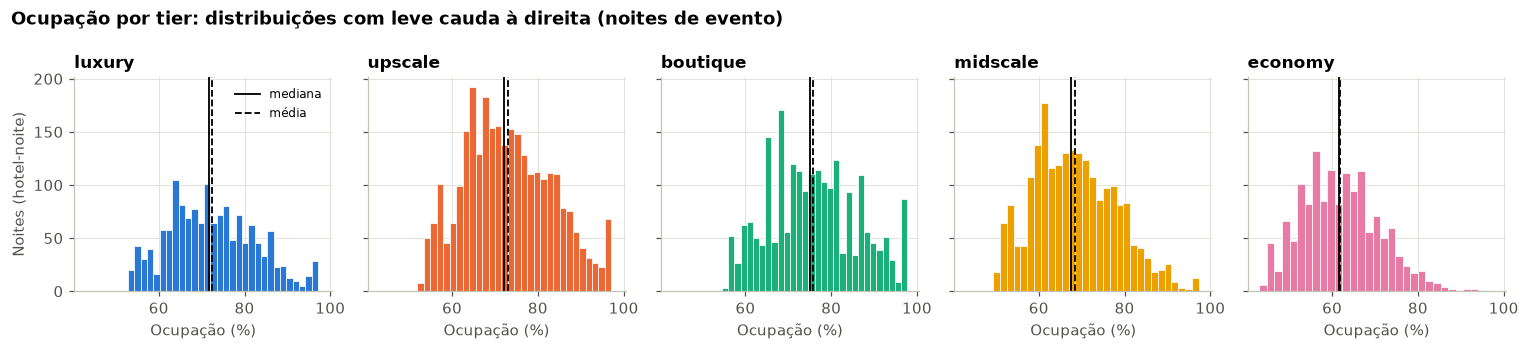

In [3]:
fig, eixos = plt.subplots(1, 5, figsize=(14, 3.2), sharex=True, sharey=True)
for eixo, tier in zip(eixos, ORDEM_TIER):
    valores = diario.loc[diario["tier"] == tier, "occupancy"] * 100
    eixo.hist(valores, bins=30, color=CORES_TIER[tier], edgecolor="white", linewidth=0.5)
    eixo.axvline(valores.median(), color="black", linewidth=1.2, label="mediana")
    eixo.axvline(valores.mean(), color="black", linewidth=1.2, linestyle="--", label="média")
    eixo.set_title(tier, fontsize=11)
    eixo.set_xlabel("Ocupação (%)")
eixos[0].set_ylabel("Noites (hotel-noite)")
eixos[0].legend(fontsize=8)
fig.suptitle("Ocupação por tier: distribuições com leve cauda à direita (noites de evento)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretação.** Nos cinco *tiers* a média fica **0,3 a 0,9 ponto percentual acima da mediana** e a assimetria é positiva: as noites de evento e de alta temporada formam uma cauda à direita. A diferença é pequena, mas a pergunta é sobre a **noite típica**, e para isso a **mediana** é a medida certa, porque não é puxada pelas noites excepcionais.

| Tier | Ocupação típica (mediana) |
|---|---|
| boutique | ~75% |
| upscale | ~72% |
| luxury | ~72% |
| midscale | ~67% |
| economy | ~62% |

Os boutiques são os que mais enchem e os econômicos os que menos.

### 1.2 Qual tier tem a diária (ADR) mais variável?

O **desvio padrão** mede a dispersão em dólares, mas cresce naturalmente com o nível de preço (10% de um resort de luxo são muito mais dólares do que 10% de um motel). Para comparar *tiers* com preços tão diferentes, a medida adequada é o **coeficiente de variação (CV = desvio / média)**, uma dispersão relativa.

Cuidado adicional: se eu calcular o desvio com **todas as noites de todos os hotéis de um tier**, misturo duas coisas: a variação **ao longo do ano** e a **diferença de preço entre hotéis** do mesmo tier. A pergunta é sobre "ao longo do ano", então calculo o CV **de cada hotel** e depois faço a média por tier.

In [4]:
variacao_agrupada = (diario.groupby("tier", observed=True)["adr"]
                     .agg(media="mean", desvio="std"))
variacao_agrupada["cv_agrupado"] = variacao_agrupada["desvio"] / variacao_agrupada["media"]

cv_por_hotel = diario.groupby(["tier", "hotel_id"], observed=True)["adr"].agg(lambda s: s.std() / s.mean())
desvio_por_hotel = diario.groupby(["tier", "hotel_id"], observed=True)["adr"].std()
variacao_agrupada["desvio_medio_por_hotel"] = desvio_por_hotel.groupby("tier", observed=True).mean()
variacao_agrupada["cv_medio_por_hotel"] = cv_por_hotel.groupby("tier", observed=True).mean()
variacao_agrupada

,media,desvio,cv_agrupado,desvio_medio_por_hotel,cv_medio_por_hotel
tier,,,,,
luxury,367.234,68.405,0.186,65.786,0.179
upscale,223.514,43.055,0.193,40.298,0.180
boutique,211.048,51.381,0.243,37.941,0.180
midscale,151.759,27.678,0.182,26.936,0.177
economy,91.215,16.559,0.182,15.774,0.173


**Interpretação.**

- **Em dólares**, o tier *luxury* é o mais variável: o desvio padrão de um hotel de luxo ao longo do ano passa de 60 USD, contra cerca de 16 USD no *economy*.
- **Em termos relativos** (CV por hotel), os cinco *tiers* variam praticamente o mesmo, cerca de **17–18%** ao longo do ano. A sazonalidade age em proporção parecida em todos.
- O tier *boutique* parece o mais variável quando todas as noites são agrupadas (CV ~0,24), mas isso é efeito da **mistura de hotéis**: os três boutiques têm preços muito diferentes entre si (The Lantern House cobra bem acima de The Foxglove). Essa é a armadilha "não misture categorias" acontecendo dentro de um mesmo tier.

**Resposta:** em valor absoluto, *luxury*. Em variação relativa ao longo do ano não há um tier claramente mais variável. A medida que mostra isso é o **coeficiente de variação calculado por hotel**.

### 1.3 Distribuição de frequências das notas

In [5]:
freq = avaliacoes["rating"].value_counts().sort_index().to_frame("freq_absoluta")
freq["freq_relativa_%"] = freq["freq_absoluta"] / freq["freq_absoluta"].sum() * 100
freq["freq_acumulada"] = freq["freq_absoluta"].cumsum()
freq["freq_rel_acumulada_%"] = freq["freq_relativa_%"].cumsum()
freq.index.name = "estrelas"
print("Total de avaliações:", freq["freq_absoluta"].sum())
freq.round(1)

Total de avaliações: 12077


,freq_absoluta,freq_relativa_%,freq_acumulada,freq_rel_acumulada_%
estrelas,,,,
1,1087,9.0,1087,9.0
2,2439,20.2,3526,29.2
3,3212,26.6,6738,55.8
4,2302,19.1,9040,74.9
5,3037,25.1,12077,100.0


In [6]:
ate_3 = freq.loc[1:3, "freq_absoluta"].sum() / freq["freq_absoluta"].sum() * 100
print(f"Avaliações com 3 estrelas ou menos: {ate_3:.1f}%")
print(f"Média: {avaliacoes['rating'].mean():.2f} | mediana: {avaliacoes['rating'].median():.0f} | moda: {avaliacoes['rating'].mode()[0]}")

Avaliações com 3 estrelas ou menos: 55.8%
Média: 3.31 | mediana: 3 | moda: 3


**Interpretação.** **55,8% das avaliações têm 3 estrelas ou menos**, um número lido direto da frequência relativa acumulada até 3. A distribuição é **bimodal**: há um pico em 3 estrelas (a moda) e outro em 5. A média de 3,31 sozinha esconde essa polarização, porque Port Alder tem muitos hóspedes satisfeitos e muitos insatisfeitos, e menos gente "no meio" do que a média sugere. Isso faz sentido, já que cada avaliação nasce de um cenário (encanto, barulho, cobrança etc.) com faixa de nota definida.

---
## 2. Sazonalidade e eventos

### 2.1 Meses e dias da semana

Uso a **média** de ocupação e de ADR por mês e por dia da semana. Aqui ela é adequada porque cada grupo tem centenas de noites e a assimetria é pequena. Como estou agregando todos os *tiers*, a **ADR** é comparada em **índice** (mês ÷ média anual de cada hotel). Assim o nível de preço do luxo não domina o resultado.

In [7]:
diario["adr_indice"] = diario["adr"] / diario.groupby("hotel_id")["adr"].transform("mean") * 100
NOMES_MES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

por_mes = diario.groupby("month").agg(ocupacao=("occupancy", "mean"), adr_indice=("adr_indice", "mean"))
por_mes.index = NOMES_MES
por_mes["ocupacao"] *= 100

ORDEM_DIAS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
DIAS_PT = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
por_dia = (diario.groupby("weekday").agg(ocupacao=("occupancy", "mean"), adr_indice=("adr_indice", "mean"))
           .reindex(ORDEM_DIAS))
por_dia.index = DIAS_PT
por_dia["ocupacao"] *= 100

print("Por mês (ocupação em %, ADR em índice 100 = média do hotel)")
print(por_mes.round(1).T)
print("\nPor dia da semana")
print(por_dia.round(1).T)

Por mês (ocupação em %, ADR em índice 100 = média do hotel)
             jan   fev   mar   abr    mai    jun    jul    ago    set   out  \
ocupacao    60.6  62.7  66.5  70.4   73.5   78.5   81.6   84.3   76.0  70.9   
adr_indice  82.8  85.9  91.0  96.9  102.4  112.5  120.3  127.2  108.5  97.6   

             nov   dez  
ocupacao    63.1  62.0  
adr_indice  85.7  87.3  

Por dia da semana
             seg   ter    qua    qui    sex    sáb   dom
ocupacao    63.3  70.3   72.3   71.7   75.6   79.8  63.4
adr_indice  90.0  98.2  101.2  100.1  109.3  116.5  84.6


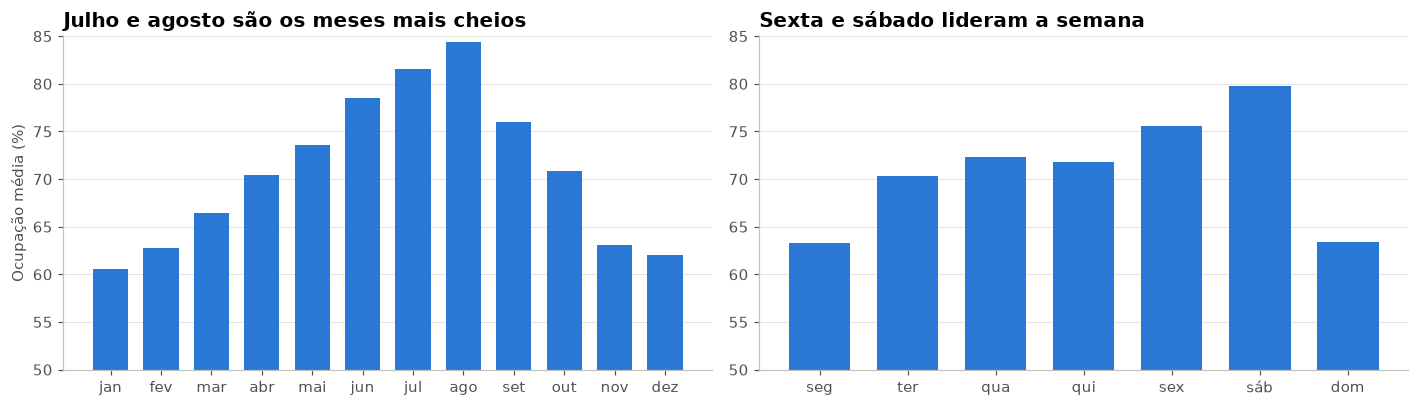

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
eixos[0].bar(por_mes.index, por_mes["ocupacao"], color=COR_BOM, width=0.7)
eixos[0].set_ylim(50, 85)
eixos[0].set_ylabel("Ocupação média (%)")
eixos[0].set_title("Julho e agosto são os meses mais cheios")
eixos[1].bar(por_dia.index, por_dia["ocupacao"], color=COR_BOM, width=0.7)
eixos[1].set_ylim(50, 85)
eixos[1].set_title("Sexta e sábado lideram a semana")
for eixo in eixos:
    eixo.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Interpretação.** O **verão (julho e agosto)** concentra a maior ocupação e a maior diária. O inverno (janeiro, novembro e dezembro) é o vale. Na semana, **sábado e sexta** lideram em ocupação e em diária, e **domingo e segunda** são os dias mais fracos. Ocupação e diária sobem e descem **juntas**: quando a demanda aperta, os hotéis cobram mais.

*Observação sobre o eixo:* o eixo vertical começa em 50% para tornar visíveis as diferenças entre meses. Em gráficos de barras isso exige cuidado, porque exagera visualmente as diferenças. No notebook 04 os gráficos de barras começam no zero.

### 2.2 Noites com evento × noites comuns, por tier

In [9]:
eventos = (diario.groupby(["tier", "tem_evento"], observed=True)
           .agg(ocupacao=("occupancy", "mean"), adr=("adr", "mean"))
           .unstack("tem_evento"))
efeito = pd.DataFrame({
    "ocupacao_comum_%": eventos[("ocupacao", False)] * 100,
    "ocupacao_evento_%": eventos[("ocupacao", True)] * 100,
    "dif_ocupacao_pp": (eventos[("ocupacao", True)] - eventos[("ocupacao", False)]) * 100,
    "adr_comum": eventos[("adr", False)],
    "adr_evento": eventos[("adr", True)],
    "dif_adr_usd": eventos[("adr", True)] - eventos[("adr", False)],
    "dif_adr_%": (eventos[("adr", True)] / eventos[("adr", False)] - 1) * 100,
})
geral = diario.groupby("tem_evento").agg(ocupacao=("occupancy", "mean"), adr=("adr", "mean"))
print(f"Mercado: noites de evento têm +{(geral.loc[True, 'ocupacao'] - geral.loc[False, 'ocupacao']) * 100:.1f} pp "
      f"de ocupação e +{(geral.loc[True, 'adr'] / geral.loc[False, 'adr'] - 1) * 100:.1f}% de ADR")
efeito.round(1)

Mercado: noites de evento têm +9.9 pp de ocupação e +20.5% de ADR


,ocupacao_comum_%,ocupacao_evento_%,dif_ocupacao_pp,adr_comum,adr_evento,dif_adr_usd,dif_adr_%
tier,,,,,,,
luxury,71.7,81.8,10.1,362.4,437.1,74.7,20.6
upscale,72.4,82.4,10.0,220.6,266.0,45.5,20.6
boutique,75.2,84.8,9.6,208.4,250.0,41.6,20.0
midscale,67.7,77.8,10.1,149.7,180.9,31.1,20.8
economy,61.3,70.6,9.2,90.0,108.2,18.2,20.2


**Interpretação.** Em média, uma noite com evento de demanda tem **cerca de 10 pontos percentuais a mais de ocupação** e uma diária **cerca de 20% mais alta**.

O efeito é **igual em termos relativos** em todos os *tiers*: +9 a +10 pp de ocupação e +20% a +21% de ADR. **Em dólares, porém, é muito desigual**: um hotel de luxo ganha cerca de 75 USD por quarto numa noite de evento, e um econômico ganha cerca de 18 USD. A resposta à pergunta "a diferença é igual em todos os tiers?" depende da escala: **igual em %, diferente em USD**.

---
## 3. Relações entre variáveis

### 3.1 Ocupação × diária: o mercado inteiro e cada tier

In [10]:
corr_mercado = diario["occupancy"].corr(diario["adr"])
corr_tier = diario.groupby("tier", observed=True).apply(lambda g: g["occupancy"].corr(g["adr"]))
corr_hotel = diario.groupby("hotel_id").apply(lambda g: g["occupancy"].corr(g["adr"]))
print(f"Correlação de Pearson no mercado inteiro: {corr_mercado:.2f}")
print("\nPor tier:")
print(corr_tier.round(2))
print(f"\nPor hotel: entre {corr_hotel.min():.2f} e {corr_hotel.max():.2f}")

Correlação de Pearson no mercado inteiro: 0.60

Por tier:
tier
luxury      0.95
upscale     0.95
boutique    0.72
midscale    0.96
economy     0.97
dtype: float64

Por hotel: entre 0.97 e 0.98


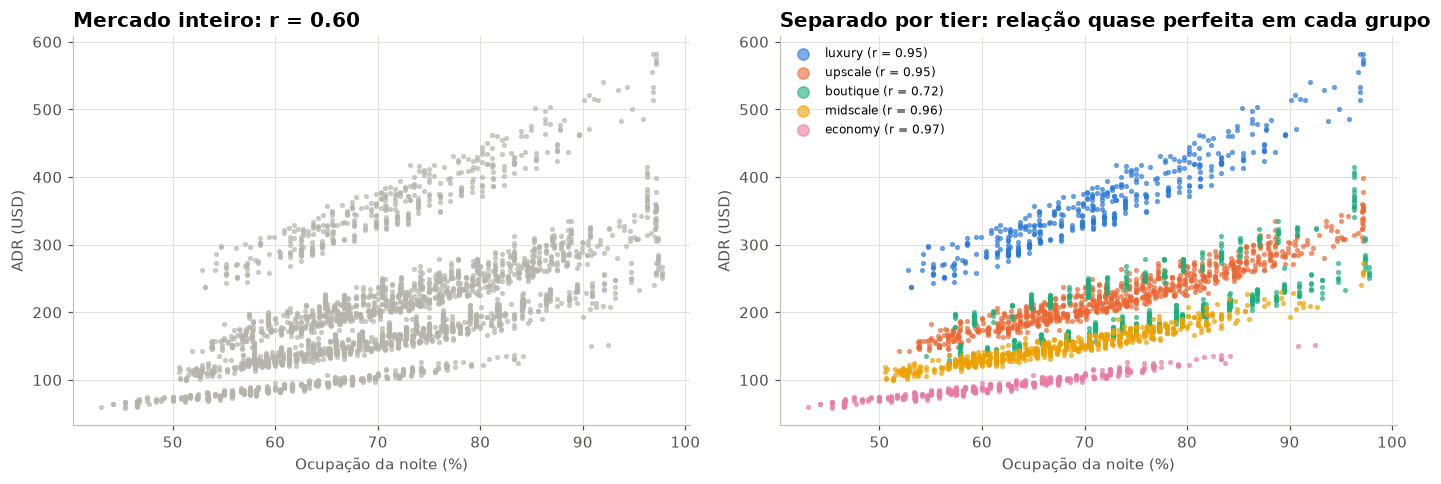

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
amostra = diario.sample(3000, random_state=1)
eixos[0].scatter(amostra["occupancy"] * 100, amostra["adr"], s=6, color=COR_NEUTRO, alpha=0.6)
eixos[0].set_title(f"Mercado inteiro: r = {corr_mercado:.2f}")
for tier in ORDEM_TIER:
    pedaco = amostra[amostra["tier"] == tier]
    eixos[1].scatter(pedaco["occupancy"] * 100, pedaco["adr"], s=6, color=CORES_TIER[tier], alpha=0.6,
                     label=f"{tier} (r = {corr_tier[tier]:.2f})")
eixos[1].set_title("Separado por tier: relação quase perfeita em cada grupo")
eixos[1].legend(markerscale=3, fontsize=8)
for eixo in eixos:
    eixo.set_xlabel("Ocupação da noite (%)")
    eixo.set_ylabel("ADR (USD)")
plt.tight_layout()
plt.show()

**Interpretação.** A correlação é **positiva** nos dois níveis, mas muito mais forte **dentro** de cada grupo: **0,60** no mercado inteiro contra **0,95–0,97** em quatro dos cinco *tiers* e 0,97–0,98 dentro de cada hotel.

O que isso revela: dentro de um hotel, noite mais cheia significa diária mais alta, porque a demanda puxa o preço. Juntar todos os *tiers* mistura **níveis de preço diferentes**: um econômico lotado cobra menos que um resort meio vazio. Essa mistura enfraquece a correlação. O boutique (0,72) fica abaixo dos demais pelo mesmo motivo, já que reúne hotéis de faixas de preço bem diferentes.

**Lição:** uma correlação calculada sobre grupos misturados pode esconder ou distorcer a relação que existe dentro de cada grupo.

### 3.2 Nota média semanal × desempenho financeiro: causal ou espúria?

Uso `weekly_performance`, que já traz a nota média da semana. As 27 semanas sem avaliação (nota nula) ficam de fora automaticamente.

In [12]:
com_nota = semanal.dropna(subset=["mean_rating"])
metricas = ["revpar", "adr", "occupancy", "total_revenue", "rgi"]
corr_geral = com_nota[metricas].corrwith(com_nota["mean_rating"])
corr_dentro = pd.DataFrame({m: com_nota.groupby("hotel_id").apply(lambda g: g["mean_rating"].corr(g[m]))
                            for m in metricas})
resultado = pd.DataFrame({"todas_as_semanas": corr_geral,
                          "media_dentro_de_cada_hotel": corr_dentro.mean(),
                          "min_hotel": corr_dentro.min(), "max_hotel": corr_dentro.max()})
print("Correlação da nota média semanal com cada métrica")
resultado.round(2)

Correlação da nota média semanal com cada métrica


,todas_as_semanas,media_dentro_de_cada_hotel,min_hotel,max_hotel
revpar,0.22,-0.01,-0.17,0.24
adr,0.25,-0.01,-0.17,0.25
occupancy,0.09,-0.01,-0.15,0.26
total_revenue,0.18,-0.01,-0.16,0.25
rgi,0.02,0.01,-0.10,0.13


In [13]:
por_hotel = (com_nota.groupby(["hotel_id", "tier"], observed=True)
             .agg(nota=("mean_rating", "mean"), revpar=("revpar", "mean")).reset_index())
print(f"Entre hotéis (14 pontos): r(nota, RevPAR) = {por_hotel['nota'].corr(por_hotel['revpar']):.2f}")
print(por_hotel.sort_values("revpar", ascending=False).round(2).to_string(index=False))

Entre hotéis (14 pontos): r(nota, RevPAR) = 0.88
hotel_id     tier  nota  revpar
     H03   luxury  3.55  287.50
     H05   luxury  3.60  256.82
     H02 boutique  3.45  201.30
     H04  upscale  3.32  188.40
     H01  upscale  3.51  172.18
     H06  upscale  3.32  160.30
     H07 boutique  3.15  154.69
     H14  upscale  3.26  149.13
     H11 boutique  3.34  137.15
     H10 midscale  3.10  112.49
     H13 midscale  3.25  106.26
     H09 midscale  3.22  100.46
     H08  economy  2.89   62.63
     H12  economy  3.05   52.98


**Interpretação.**

- Juntando todas as semanas, a correlação entre nota e RevPAR é **fraca e positiva (≈ 0,22)**.
- **Dentro de cada hotel ela desaparece** (média ≈ 0, variando de cerca de −0,2 a +0,25): uma semana com nota melhor **não** tem RevPAR melhor no mesmo hotel.
- **Entre hotéis**, comparando as médias dos 14, ela é forte (≈ 0,88). A correlação geral vem dessas **diferenças entre hotéis**: os hotéis de luxo e upscale têm, ao mesmo tempo, notas um pouco mais altas e RevPAR muito mais alto. Hotéis econômicos recebem mais avaliações de barulho, limpeza e cobrança e cobram menos. O *tier* é uma **terceira variável** que puxa as duas.

**Conclusão:** a relação semanal é **espúria** (efeito de confusão pelo *tier*), e não há base para dizer que melhorar a nota de uma semana aumenta a receita da mesma semana. Uma relação causal, se existir, agiria **com atraso** (reputação acumulada ao longo de meses), e mesmo assim exigiria um desenho que controlasse o *tier*. Este notebook não tem esse desenho. Além disso, o dataset é sintético, e o README não diz que a nota foi simulada como causa da receita.

### 3.3 Quais notas parciais andam mais junto com a nota geral?

In [14]:
parciais = ["cleanliness", "comfort", "service_score", "location_score", "value_score", "sleep_quality"]
corr_parciais = avaliacoes[parciais].corrwith(avaliacoes["rating"]).sort_values(ascending=False)
corr_parciais.round(3).to_frame("correlacao_com_nota_geral")

,correlacao_com_nota_geral
cleanliness,0.901
comfort,0.885
service_score,0.878
sleep_quality,0.867
value_score,0.809
location_score,0.166


**Interpretação.** **Limpeza (0,90), conforto (0,88) e serviço (0,88)** são as notas parciais mais ligadas à nota geral, seguidas de sono e custo-benefício (≈ 0,81–0,87). **Localização quase não se relaciona (0,17)**: os hotéis não mudam de lugar, e a localização é avaliada de forma parecida em hóspedes satisfeitos e insatisfeitos. Para um gerente, isso aponta onde agir: limpeza, conforto e serviço.

---
## 4. Projeção para 2029 (extrapolação)

Escolhi o **Marisol Bay Resort (H03)**, o hotel de maior receita. Primeiro olho a série mensal de receita total (quartos + extras).

In [15]:
h03 = diario[diario["hotel_id"] == "H03"].copy()
h03["receita_total"] = h03["room_revenue"] + h03["ancillary_revenue"]
anual = h03.groupby("year").agg(receita=("receita_total", "sum"), noites=("date", "nunique"))
anual["receita_por_noite"] = anual["receita"] / anual["noites"]
print(anual.assign(receita_mi_usd=anual["receita"] / 1e6).drop(columns="receita")
      .round({"receita_mi_usd": 2, "receita_por_noite": 0}))
print(f"\nCrescimento da receita anual:   {(anual.loc[2028, 'receita'] / anual.loc[2027, 'receita'] - 1) * 100:+.2f}%")
print(f"Crescimento da receita por noite: {(anual.loc[2028, 'receita_por_noite'] / anual.loc[2027, 'receita_por_noite'] - 1) * 100:+.2f}%")

      noites  receita_por_noite  receita_mi_usd
year                                           
2027     362            72152.0           26.12
2028     366            72085.0           26.38

Crescimento da receita anual:   +1.01%
Crescimento da receita por noite: -0.09%


**Armadilha encontrada:** os anos não têm o mesmo número de noites. Os dados começam em **4 de janeiro de 2027** (362 noites), e **2028 é bissexto** (366 noites). O "crescimento" de ~1% da receita anual é quase todo **efeito de calendário**: por noite, a receita ficou praticamente estável (−0,1%). Por isso a projeção trabalha com **receita média por noite** e só no fim multiplica pelo número de dias de cada mês de 2029.

**Método escolhido: sazonal ingênuo com crescimento.** A receita tem sazonalidade muito forte (uma noite de agosto rende cerca do dobro de uma de janeiro). Uma reta ajustada aos 24 meses ignora isso. Então:

> receita de 2029 no mês *m* = receita média por noite em *m*/2028 × (1 + crescimento por noite) × dias de *m* em 2029

Para comparar, também ajusto uma **reta** (regressão linear simples) à receita média por noite dos 24 meses e a estendo para os 12 seguintes.

Receita 2028 realizada:        26.38 mi USD
2029 sazonal com crescimento:  26.30 mi USD
2029 pela reta:                27.84 mi USD  (a reta sobe 241 USD por noite a cada mês)


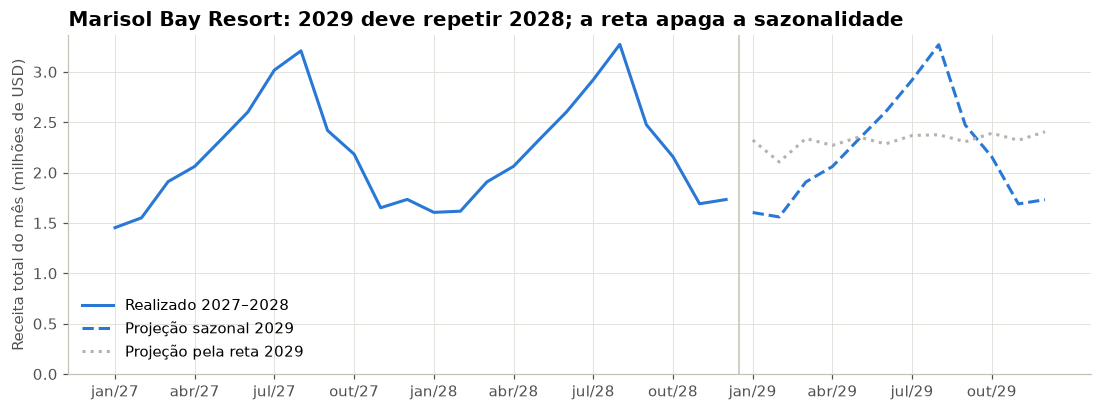

In [16]:
por_noite = h03.groupby(["year", "month"])["receita_total"].mean().unstack("year")
por_noite.index = NOMES_MES
cresc_noite = anual.loc[2028, "receita_por_noite"] / anual.loc[2027, "receita_por_noite"] - 1
dias_2029 = pd.Series([pd.Period(f"2029-{m:02d}").days_in_month for m in range(1, 13)], index=NOMES_MES)

proj_sazonal = por_noite[2028] * (1 + cresc_noite) * dias_2029

serie = pd.concat([por_noite[2027], por_noite[2028]]).to_numpy()
inclinacao, intercepto = np.polyfit(np.arange(24), serie, 1)
proj_reta = (intercepto + inclinacao * np.arange(24, 36)) * dias_2029.to_numpy()

print(f"Receita 2028 realizada:        {anual.loc[2028, 'receita'] / 1e6:.2f} mi USD")
print(f"2029 sazonal com crescimento:  {proj_sazonal.sum() / 1e6:.2f} mi USD")
print(f"2029 pela reta:                {proj_reta.sum() / 1e6:.2f} mi USD  "
      f"(a reta sobe {inclinacao:,.0f} USD por noite a cada mês)")

realizado_mes = h03.groupby(["year", "month"])["receita_total"].sum().to_numpy()
fig, eixo = plt.subplots(figsize=(12, 4))
eixo.plot(range(24), realizado_mes / 1e6, color=CORES_TIER["luxury"], linewidth=2, label="Realizado 2027–2028")
eixo.plot(range(24, 36), proj_sazonal.to_numpy() / 1e6, color=CORES_TIER["luxury"], linewidth=2,
          linestyle="--", label="Projeção sazonal 2029")
eixo.plot(range(24, 36), proj_reta / 1e6, color=COR_NEUTRO, linewidth=2, linestyle=":",
          label="Projeção pela reta 2029")
eixo.axvline(23.5, color="#c3c2b7", linewidth=1)
eixo.set_xticks(range(0, 36, 3))
eixo.set_xticklabels([f"{NOMES_MES[m % 12]}/{27 + m // 12}" for m in range(0, 36, 3)])
eixo.set_ylabel("Receita total do mês (milhões de USD)")
eixo.set_ylim(0)
eixo.set_title("Marisol Bay Resort: 2029 deve repetir 2028; a reta apaga a sazonalidade")
eixo.legend()
plt.show()

**Resultado.** A projeção sazonal dá **cerca de 26,3 milhões de USD** para 2029, praticamente o mesmo de 2028, porque a receita por noite não cresceu. A reta dá um total mais alto e prevê um ano **sem sazonalidade**, o que é falso mês a mês: subestima o verão e superestima o inverno. A inclinação positiva da reta não indica crescimento real: ela aparece porque o pico de cada ano (julho e agosto) fica na segunda metade do ano, e a reta "lê" isso como tendência de alta. A projeção sazonal é a mais útil para planejar.

**Limitações: por que essa projeção é frágil**

1. **Só dois anos de histórico.** Uma taxa de crescimento calculada com dois pontos não é uma tendência. Um ano atípico mudaria tudo.
2. **Calendário desigual:** anos com número diferente de noites (362 × 366) distorcem comparações de totais. Foi preciso corrigir pela receita por noite.
3. **Extrapolação, não interpolação.** Estamos fora do intervalo observado, e nada garante que o padrão se mantenha.
4. **Ignora choques e decisões:** novos concorrentes, reformas, crises de demanda, mudanças na política de preços.
5. **Eventos supostos fixos:** a projeção assume os mesmos eventos (Regatta Week etc.) nas mesmas datas e com o mesmo efeito.
6. **Sem intervalo de confiança:** o número único passa uma falsa precisão.
7. **Dados sintéticos:** a simulação foi construída sem tendência de longo prazo. A projeção reflete a regra do simulador, não o mercado real.

---
## 5. Conclusão (uma página)

**Retrato do mercado.** A ocupação típica (mediana) vai de ~62% no *economy* a ~75% no *boutique*. A mediana é preferível à média porque as noites de evento criam uma cauda à direita. Em dólares, a diária do *luxury* é a mais variável. Em termos relativos, todos os *tiers* oscilam ~17–18% ao longo do ano, e o *boutique* só parece mais variável quando hotéis de preços diferentes são misturados. Nas avaliações, **55,8% têm 3 estrelas ou menos**, e a distribuição é polarizada, com picos em 3 e 5 estrelas.

**Sazonalidade e eventos.** Julho e agosto, e sexta e sábado, concentram ocupação e diária. Noites com evento somam ~10 pp de ocupação e ~20% de diária em **todos** os *tiers*. O efeito é igual em percentual e muito diferente em dólares.

**Relações.** Ocupação e diária andam juntas (r ≈ 0,95 dentro de cada tier, 0,60 no mercado misturado): misturar grupos enfraquece correlações. A correlação entre nota semanal e RevPAR (0,22) é **espúria**, porque desaparece dentro de cada hotel e é explicada pelo *tier*. Limpeza, conforto e serviço são as dimensões que mais acompanham a nota geral, e localização quase não pesa.

**Projeção.** O Marisol Bay Resort deve faturar ~26,3 mi USD em 2029 se repetir 2028. O aparente crescimento de 1% de 2027 para 2028 era efeito de calendário (362 × 366 noites). A projeção é frágil (dois anos, sem intervalo, dados sintéticos) e serve como cenário de referência, não como previsão.

**Implicação para as próximas etapas:** toda comparação de preço deve ser feita **dentro do tier** e contra os concorrentes diretos (índices ARI, MPI e RGI), que é o que o painel e o mapa de posicionamento fazem.